# Figure 2D：反向条件分段回归补充验证

本 notebook 实际重新拟合六个模型，不仅载入已有结果。固定 PIU=30 节点，五个连续表型使用 OLS，Sex 使用二项 Logistic GLM；六个斜率变化检验统一 BH-FDR。无其他协变量、阈值搜索或模拟。

这是探索性 `E(X | PIU)` 分析，不能替代或推翻此前 `E(PIU | X)` 截断模拟。Sex 的 statsmodels HC3 参数存在实现限制，见后文说明。

输入沿用同一 1,114 人样本；全部表格、图及元数据写入 `CPM_Validation_rangeRestriction/`。

## 1. 环境与输入输出路径

In [1]:
import argparse, hashlib, json, platform, sys
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy.stats import rankdata
import statsmodels
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
# 自动定位项目根目录，支持从 CPM/ 或项目根目录启动。
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'AGENTS.md').exists() and (p/'Scripts/biox').is_dir())
sys.path.insert(0, str(ROOT/'Scripts/CPM_commonMappingNull'))
from phenotype import COLS, phenotype_design
from types import SimpleNamespace
from IPython.display import display, Image, Markdown
NAMES = ['Age','Sex','Education','Occupation','CBCL_Int','CBCL_Ext']
INPUT = ROOT/'tmpt/CPM/CPM_Validation_pooledModel/sample_metadata.csv'
out = ROOT/'tmpt/CPM/CPM_Validation_rangeRestriction'
out.mkdir(parents=True, exist_ok=True)
a = SimpleNamespace(input=INPUT)
SCRIPT = ROOT/'Scripts/CPM/validation_reverse_piecewise/run_reverse_piecewise.py'
# 重跑本 notebook 会重新计算并更新此专用目录；不覆盖前次独立分析目录。


## 2. 样本核验与全样本预处理

In [2]:
df=pd.read_csv(a.input,dtype={'ID':str}); columns=['IAT_PCIAT_Total']+COLS
audit=pd.DataFrame({'column':columns,'missing':[df[c].isna().sum() for c in columns],'nonfinite':[int((~np.isfinite(df[c].to_numpy(float))).sum()) for c in columns]})
audit.to_csv(out/'input_audit.csv',index=False)
if audit.nonfinite.sum(): raise ValueError('缺失或非有限值；不删除样本，详见 input_audit.csv')
if df.ID.isna().any() or df.ID.duplicated().any(): raise ValueError('ID缺失或重复')
y=df.IAT_PCIAT_Total.to_numpy(float)
if len(y)!=1114 or sum(y<=30)!=653 or sum(y>30)!=461: raise ValueError('样本/分组数量不符')
digest=hashlib.sha256(a.input.read_bytes()).hexdigest()
oldmeta=json.loads((ROOT/'tmpt/old/range_restriction_validation_v2/run_metadata.json').read_text())
if digest!=oldmeta['input_sha256']: raise ValueError('与此前验证样本哈希不符')
if set(df[COLS[1]].unique())!={0,1}: raise ValueError('Sex必须为0/1')
x=phenotype_design(df)
# Independent check of the reused original whole-sample preprocessing.
for j,c in enumerate(COLS):
    v=df[c].to_numpy(float)
    if j in [2,3]: v=rankdata(v,method='average')
    if j!=1: v=(v-v.mean())/v.std(ddof=0)
    if not np.allclose(v,x[:,j],atol=1e-12): raise ValueError('预处理不一致: '+c)


## 3. 固定节点设计矩阵与预测网格

In [3]:
z=y-30; design=np.c_[np.ones(len(y)),z,np.maximum(z,0)]
grid=np.unique(np.r_[np.linspace(y.min(),y.max(),401),30.]); gz=grid-30
grid_design=np.c_[np.ones(len(grid)),gz,np.maximum(gz,0)]


## 4. 六个独立模型：估计、斜率与绘图

In [4]:
rows=[]; predictions=[]
plt.rcParams.update({'font.family':'Arial','font.size':10,'pdf.fonttype':42,'svg.fonttype':'none'})
fig,axes=plt.subplots(3,2,figsize=(11,10))
for j,name in enumerate(NAMES):
    fit=(sm.GLM(x[:,j],design,family=sm.families.Binomial()).fit(cov_type='HC3') if name=='Sex' else sm.OLS(x[:,j],design).fit(cov_type='HC3'))
    if name=='Sex' and not fit.converged: raise ValueError('Sex GLM未收敛')
    ci=fit.conf_int()[2]; pred=fit.predict(grid_design)
    # No intercept jump exists: both branches at the knot equal alpha.
    alpha,low,change=fit.params
    assert np.isclose(alpha+low*0,alpha+(low+change)*0)
    if name=='Sex': assert ((pred>0)&(pred<1)).all()
    rows.append(dict(variable=name,model='Binomial GLM logit' if name=='Sex' else 'OLS',n=int(fit.nobs),cov_type=fit.cov_type,scale='log-odds per PIU point' if name=='Sex' else 'SD per PIU point',intercept=alpha,slope_low=low,slope_high=low+change,slope_change=change,se=fit.bse[2],statistic=fit.tvalues[2],p=fit.pvalues[2],ci_low=ci[0],ci_high=ci[1],exp_slope_change=np.exp(change) if name=='Sex' else np.nan))
    predictions.extend(dict(variable=name,PIU=t,prediction=v) for t,v in zip(grid,pred))
    ax=axes.flat[j]
    ax.scatter(y,x[:,j],s=6,alpha=.14,color='#687886',rasterized=True)
    ax.plot(grid,pred,color='#226A93',lw=2);ax.axvline(30,color='#666666',ls='--',lw=1)
    ax.set(title=name,xlabel='PIU score',ylabel='P(Male)' if name=='Sex' else ('Whole-sample rank (z-score)' if j in [2,3] else name+' (z-score)'))
    if name=='Sex': ax.set_ylim(-.05,1.05)
    ax.spines[['top','right']].set_visible(False)


## 5. 六项 BH-FDR、独立基准与结果保存

In [5]:
result=pd.DataFrame(rows); result['q_BH6']=multipletests(result.p,method='fdr_bh')[1];result['significant_FDR']=result.q_BH6<.05
# Rounded external benchmarks are used only for validation, never as outputs.
benchmarks=pd.DataFrame({'variable':NAMES,'beta_reference':[-.01505272,.01250479,-.00385816,-.01539401,.02158702,.01842828],'p_reference':[.00628483,.37400527,.579763,.02563148,.00033276,.00309573],'q_reference':[.01256966,.44880633,.579763,.03844722,.00199657,.00928720]})
benchmarks['beta_error']=result.slope_change-benchmarks.beta_reference;benchmarks['p_error']=result.p-benchmarks.p_reference;benchmarks['q_error']=result.q_BH6-benchmarks.q_reference
benchmarks.to_csv(out/'benchmark_comparison.csv',index=False)
result.to_csv(out/'reverse_piecewise_results.csv',index=False)
if benchmarks.beta_error.abs().max()>1e-6 or benchmarks[['p_error','q_error']].abs().max().max()>1e-5: raise ValueError('基准复现失败，详见 benchmark_comparison.csv')
slopes=np.array([[.03769163,.02263891],[-.00031805,-.00417621],[.00586501,-.00952899],[.00587654,.02746356],[.00602798,.02445625]])
assert np.allclose(result.loc[result.variable!='Sex',['slope_low','slope_high']],slopes,atol=1e-6,rtol=0)
pd.DataFrame(predictions).to_csv(out/'fitted_curves.csv',index=False)
fig.tight_layout()
fig.savefig(out/'figure_reverse_piecewise.png',dpi=300)
fig.savefig(out/'figure_reverse_piecewise.pdf')
fig.savefig(out/'figure_reverse_piecewise.svg');plt.close(fig)


## 6. 与原稿及既有截断模拟并列比较

In [6]:
original=pd.read_csv(ROOT/'tmpt/old/range_restriction_validation/observed_interactions.csv')
mc=pd.read_csv(ROOT/'tmpt/old/range_restriction_validation_quartile/quartile_validation_results.csv')
comparison=result[['variable','slope_change','p','q_BH6']].merge(original[['variable','beta3','p_HC3','p_HC3_BH']],on='variable').merge(mc[['variable','p_cal','q_BH','calibration_status']],on='variable')
comparison.to_csv(out/'original_MC_reverse_comparison.csv',index=False)


## 7. 协方差实现说明与运行元数据

In [7]:
note = ('本次严格使用任务书 GLM.fit(cov_type="HC3")。在 statsmodels 0.14.0 中，GLMResults 无 cov_HC3 属性，statsmodels.base.covtype.get_robustcov_results 因此回退到 cov_white_simple(use_correction=False)，即未作杠杆HC3修正的score-sandwich。Sex基准数值对应此实现；没有擅自改成另一套协方差。五个OLS结局使用真正的OLS HC3。写论文时应区分“请求HC3”与GLM实际实现，不应笼统称六项均为杠杆修正HC3。')
(out/'covariance_implementation_note.txt').write_text(note,encoding='utf-8')
metadata=dict(input=str(a.input.resolve()),sha256=digest,n=len(y),n_low=int(sum(y<=30)),n_high=int(sum(y>30)),knot=30,design=['intercept','PIU-30','max(PIU-30,0)'],covariance_request='HC3',sex_implementation_note='statsmodels GLM robust covariance uses its installed sandwich implementation; see covariance_implementation_note.txt',tests='two-sided normal Wald; six hinge terms BH-FDR',preprocessing='whole sample ddof=0; Education/Occupation average rank then z; Sex raw 0/1',exploratory=True,versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'scipy':scipy.__version__,'statsmodels':statsmodels.__version__,'matplotlib':matplotlib.__version__},script_sha256=hashlib.sha256(SCRIPT.read_bytes()).hexdigest())
(out/'run_metadata.json').write_text(json.dumps(metadata,indent=2))


936

## 8. 中文报告与结果展示

In [8]:
text=['# 反向条件分段回归：探索性补充分析','模型 X ~ 1 + (PIU−30) + max(PIU−30,0)，固定节点30，无截距跳跃。五个连续表型 OLS；Sex 二项 GLM/logit。均按任务书调用 cov_type="HC3"，六个斜率变化项双侧检验统一BH。未添加协变量或其他模型。',
'预处理：全样本标准化 ddof=0；Education/Occupation 全样本 average rank 后标准化；Sex原始0/1，1=Male。输入1114人，无缺失或删除，低组653、高组461；哈希与先前样本一致。',
'|变量|斜率变化|SE|95% CI|P|q|','|---|---:|---:|---|---:|---:|']
for r in result.itertuples(): text.append(f'|{r.variable}|{r.slope_change:.9f}|{r.se:.9f}|[{r.ci_low:.9f}, {r.ci_high:.9f}]|{r.p:.9g}|{r.q_BH6:.9g}|')
text+=['','Age、Occupation、CBCL_Int、CBCL_Ext 的六项FDR后显著，与原稿四项模式一致。Sex/Education未显著。连续结果系数单位是每1 PIU分对应表型SD变化；Sex是log-odds斜率差，exp(γ2)不是原稿交互OR。',
'本模型阈值来自解释变量PIU，因此避免直接按本模型结局分组。但估计的是 E(X|PIU)，不是 E(PIU|X) 的等价重参数化或偏倚校正。两个方向的线性假设不等价。Age作为结局只描述年龄条件分布，绝不表示PIU导致年龄变化。',
'此前四分位截断模拟六项FDR均未显著，Age P≈0.0392、q≈0.2352；其五分位校准失败记录保留。反向结果不推翻这些模拟，不证明原始交互独立于range restriction，也不确立30分生物学转折或不同机制。',
'这是查看既有结果后提出的补充探索性分析，不是预注册或确认性检验，也不是regression discontinuity design。图示为实际模型点预测，不含置信带；Sex曲线为男性概率，散点为0/1观察。',
'基准系数、P、q及两侧斜率均在任务书容差内复现；连续性、概率范围和BH校正已检查。完整未舍入结果见CSV；原稿与模拟并列表见 original_MC_reverse_comparison.csv。Sex协方差实现细节见 covariance_implementation_note.txt。']
(out/'README_reverse_piecewise.md').write_text('\n\n'.join(text),encoding='utf-8')
print(result.to_string(index=False))


  variable              model    n cov_type                  scale  intercept  slope_low  slope_high  slope_change       se  statistic        p    ci_low   ci_high  exp_slope_change    q_BH6  significant_FDR
       Age                OLS 1114      HC3       SD per PIU point   0.168036   0.037692    0.022639     -0.015053 0.005509  -2.732539 0.006285 -0.025850 -0.004256               NaN 0.012570             True
       Sex Binomial GLM logit 1114      HC3 log-odds per PIU point  -0.496173  -0.024732   -0.012227      0.012505 0.014066   0.888996 0.374005 -0.015064  0.040074          1.012583 0.448806            False
 Education                OLS 1114      HC3       SD per PIU point   0.017603  -0.000318   -0.004176     -0.003858 0.006968  -0.553731 0.579763 -0.017514  0.009798               NaN 0.579763            False
Occupation                OLS 1114      HC3       SD per PIU point   0.088442   0.005865   -0.009529     -0.015394 0.006898  -2.231750 0.025631 -0.028913 -0.001875     

,variable,slope_low,slope_high,slope_change,se,ci_low,ci_high,p,q_BH6,significant_FDR
0,Age,0.037692,0.022639,-0.015053,0.005509,-0.025850,-0.004256,0.006285,0.012570,True
1,Sex,-0.024732,-0.012227,0.012505,0.014066,-0.015064,0.040074,0.374005,0.448806,False
2,Education,-0.000318,-0.004176,-0.003858,0.006968,-0.017514,0.009798,0.579763,0.579763,False
3,Occupation,0.005865,-0.009529,-0.015394,0.006898,-0.028913,-0.001875,0.025631,0.038447,True
4,CBCL_Int,0.005877,0.027464,0.021587,0.006016,0.009796,0.033378,0.000333,0.001997,True
5,CBCL_Ext,0.006028,0.024456,0.018428,0.006230,0.006218,0.030639,0.003096,0.009287,True


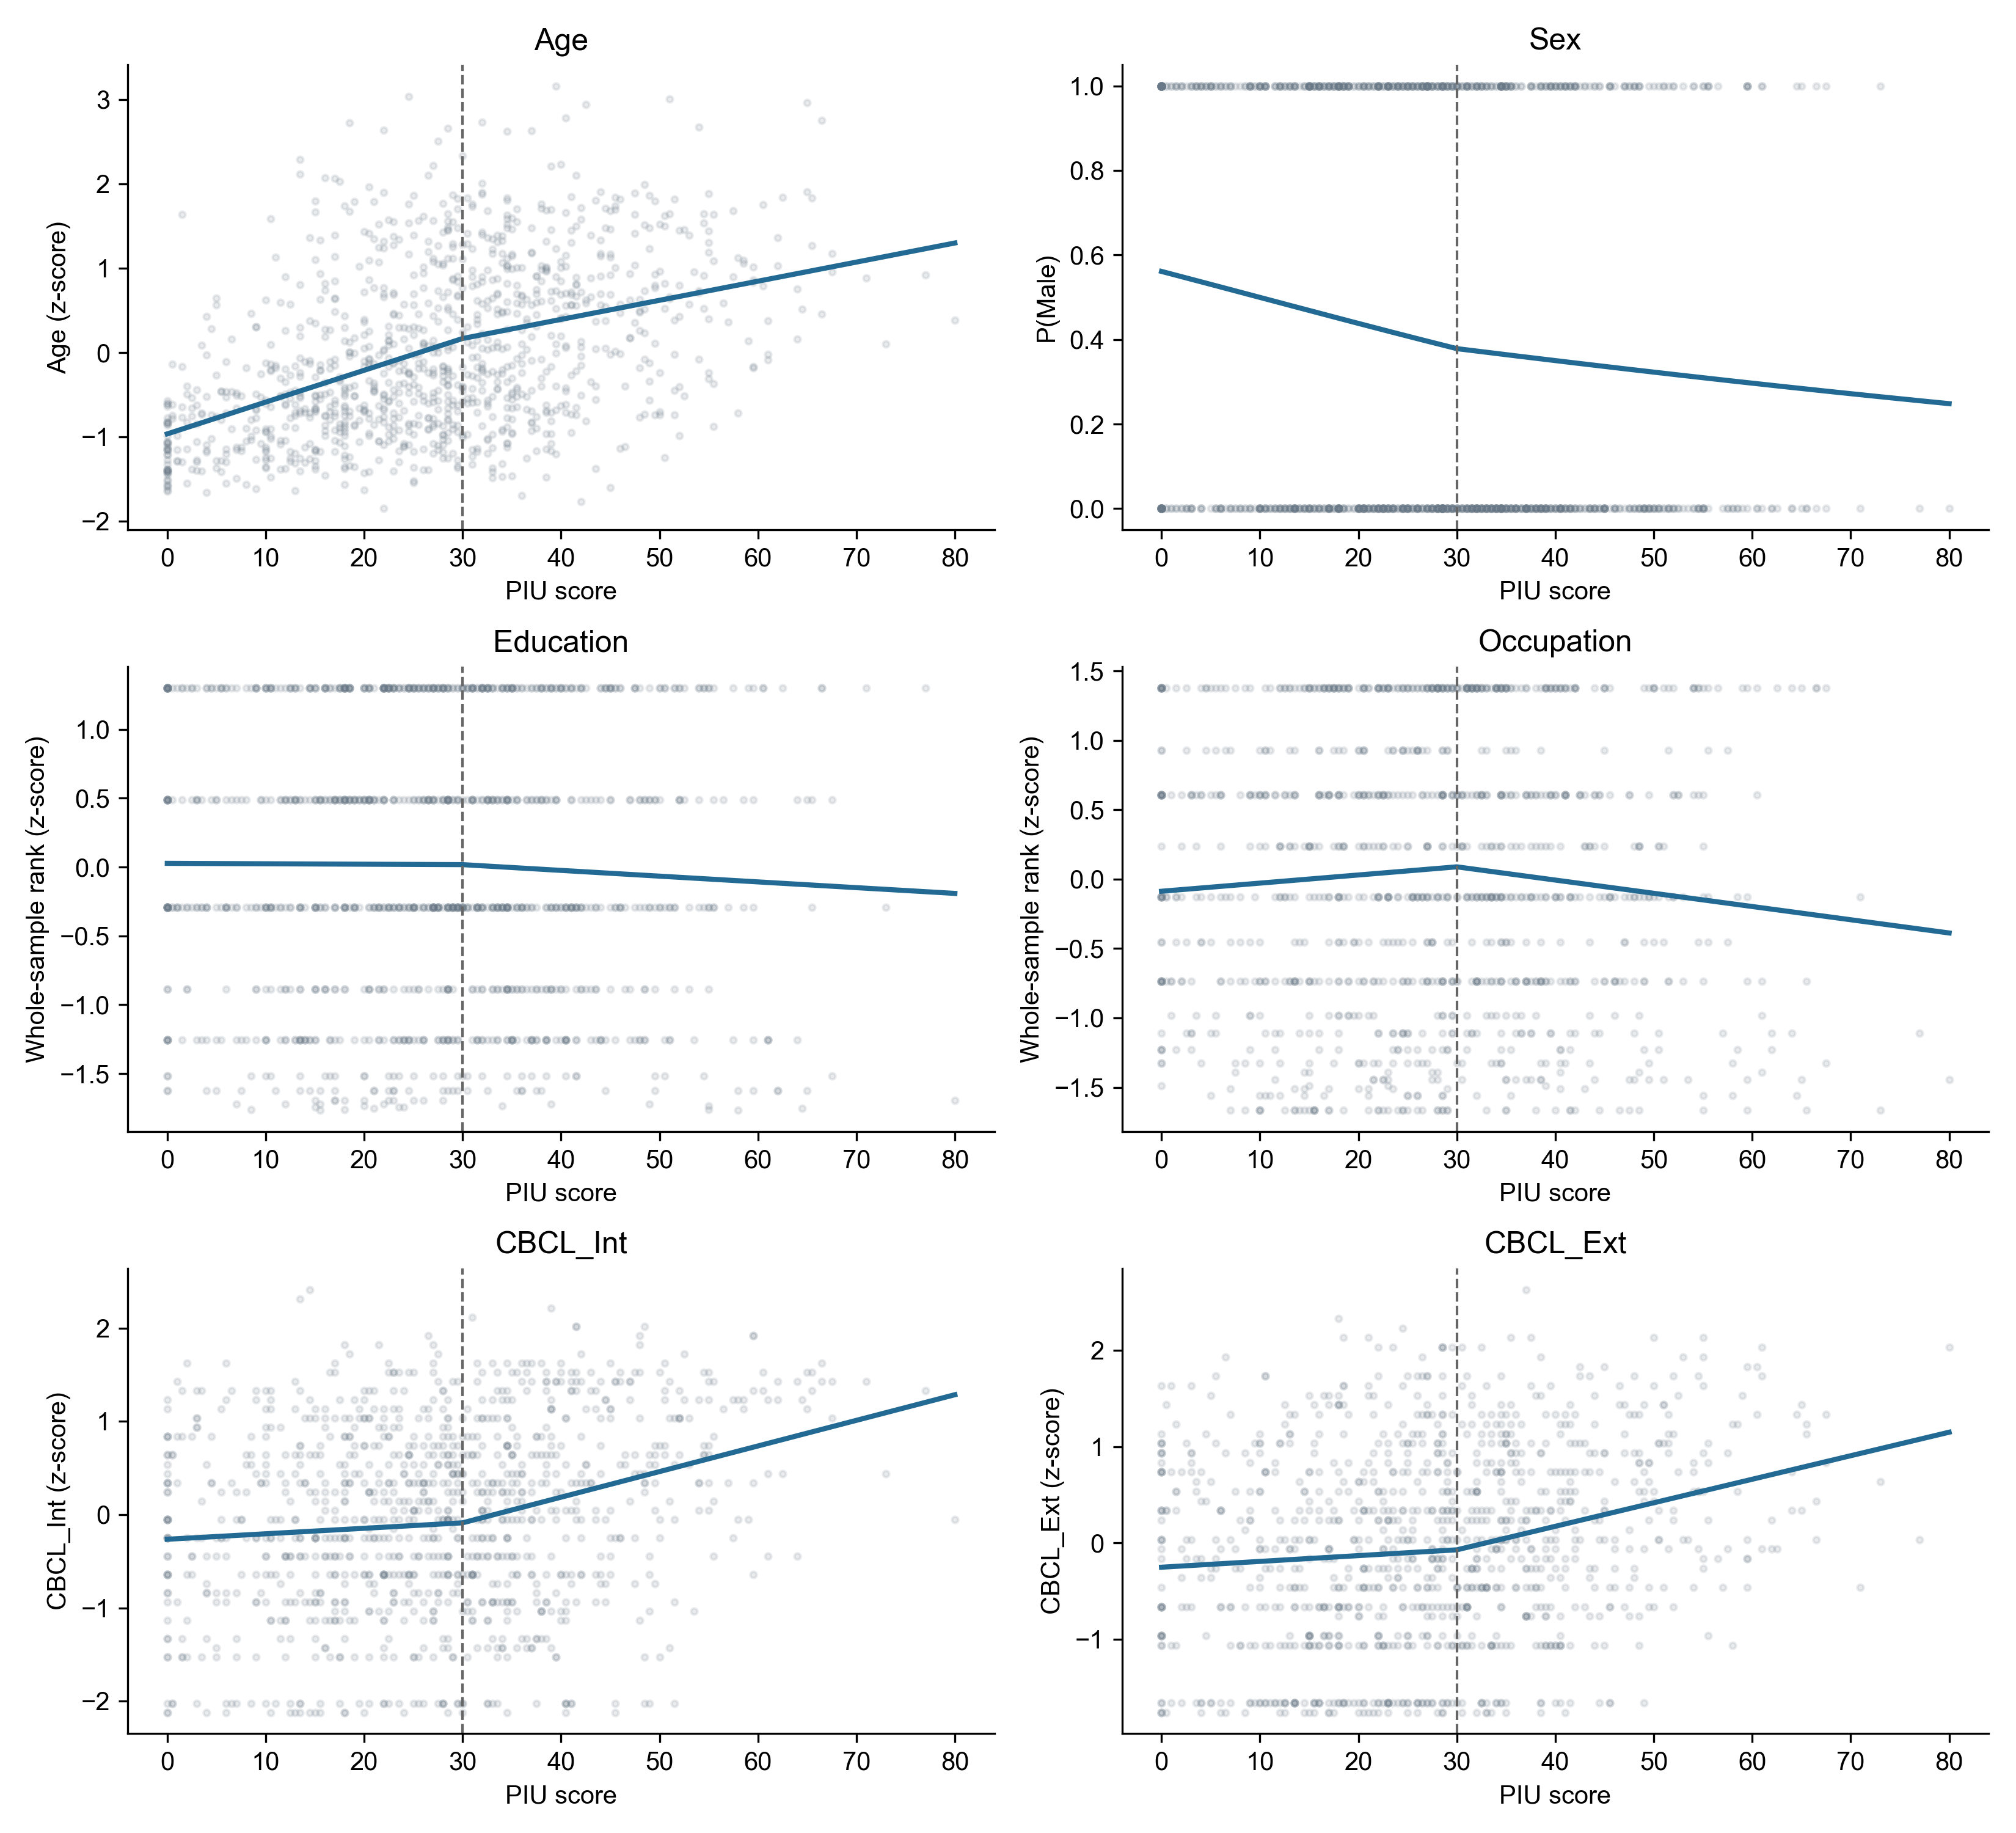

# 反向条件分段回归：探索性补充分析

模型 X ~ 1 + (PIU−30) + max(PIU−30,0)，固定节点30，无截距跳跃。五个连续表型 OLS；Sex 二项 GLM/logit。均按任务书调用 cov_type="HC3"，六个斜率变化项双侧检验统一BH。未添加协变量或其他模型。

预处理：全样本标准化 ddof=0；Education/Occupation 全样本 average rank 后标准化；Sex原始0/1，1=Male。输入1114人，无缺失或删除，低组653、高组461；哈希与先前样本一致。

|变量|斜率变化|SE|95% CI|P|q|

|---|---:|---:|---|---:|---:|

|Age|-0.015052721|0.005508695|[-0.025849565, -0.004255878]|0.00628483016|0.0125696603|

|Sex|0.012504786|0.014066191|[-0.015064441, 0.040074013]|0.374005273|0.448806327|

|Education|-0.003858160|0.006967572|[-0.017514351, 0.009798030]|0.579762996|0.579762996|

|Occupation|-0.015394007|0.006897728|[-0.028913306, -0.001874707]|0.0256314775|0.0384472162|

|CBCL_Int|0.021587019|0.006015842|[0.009796185, 0.033377852]|0.000332761947|0.00199657168|

|CBCL_Ext|0.018428276|0.006229834|[0.006218026, 0.030638525]|0.00309573173|0.00928719519|



Age、Occupation、CBCL_Int、CBCL_Ext 的六项FDR后显著，与原稿四项模式一致。Sex/Education未显著。连续结果系数单位是每1 PIU分对应表型SD变化；Sex是log-odds斜率差，exp(γ2)不是原稿交互OR。

本模型阈值来自解释变量PIU，因此避免直接按本模型结局分组。但估计的是 E(X|PIU)，不是 E(PIU|X) 的等价重参数化或偏倚校正。两个方向的线性假设不等价。Age作为结局只描述年龄条件分布，绝不表示PIU导致年龄变化。

此前四分位截断模拟六项FDR均未显著，Age P≈0.0392、q≈0.2352；其五分位校准失败记录保留。反向结果不推翻这些模拟，不证明原始交互独立于range restriction，也不确立30分生物学转折或不同机制。

这是查看既有结果后提出的补充探索性分析，不是预注册或确认性检验，也不是regression discontinuity design。图示为实际模型点预测，不含置信带；Sex曲线为男性概率，散点为0/1观察。

基准系数、P、q及两侧斜率均在任务书容差内复现；连续性、概率范围和BH校正已检查。完整未舍入结果见CSV；原稿与模拟并列表见 original_MC_reverse_comparison.csv。Sex协方差实现细节见 covariance_implementation_note.txt。

**协方差实现核查：** 本次严格使用任务书 GLM.fit(cov_type="HC3")。在 statsmodels 0.14.0 中，GLMResults 无 cov_HC3 属性，statsmodels.base.covtype.get_robustcov_results 因此回退到 cov_white_simple(use_correction=False)，即未作杠杆HC3修正的score-sandwich。Sex基准数值对应此实现；没有擅自改成另一套协方差。五个OLS结局使用真正的OLS HC3。写论文时应区分“请求HC3”与GLM实际实现，不应笼统称六项均为杠杆修正HC3。

验证通过：六项系数、SE、P、q及置信区间与独立脚本结果一致。


In [9]:
display(result[['variable','slope_low','slope_high','slope_change','se','ci_low','ci_high','p','q_BH6','significant_FDR']])
display(Image(filename=str(out/'figure_reverse_piecewise.png')))
display(Markdown((out/'README_reverse_piecewise.md').read_text()))
display(Markdown('**协方差实现核查：** '+note))
# 与保留的独立脚本运行结果逐项核对，确保 notebook 转换未改变模型。
previous = pd.read_csv(ROOT/'tmpt/CPM/validation_reverse_piecewise/reverse_piecewise_results.csv')
check_columns = ['slope_low','slope_high','slope_change','se','p','q_BH6','ci_low','ci_high']
assert np.allclose(result[check_columns], previous[check_columns], atol=1e-12, rtol=1e-10)
assert np.allclose(result.q_BH6, multipletests(result.p, method='fdr_bh')[1])
(out/'notebook_verification.json').write_text(json.dumps({'matches_retained_script_results': True, 'BH_rechecked': True, 'n': len(y), 'n_models': len(result)}, indent=2))
print('验证通过：六项系数、SE、P、q及置信区间与独立脚本结果一致。')